# Nine-frame helmet impact exploration

Inspect the temporal dataset before Colab training. This notebook performs read-only
video checks and model forward passes only. It never trains or downloads weights.

First run `python -m src.impact.dataset` from the repository root. See
[`docs/temporal_impact_colab.md`](../docs/temporal_impact_colab.md) for data conventions
and the later, explicit training command.

In [1]:
from pathlib import Path
import sys, json
root = Path.cwd().resolve()
if not (root / 'src').is_dir():
    root = root.parent
assert (root / 'src' / 'impact').is_dir(), 'Open from the repo or notebooks directory'
sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import torch
from torch.utils.data import DataLoader
from src.impact.common import load_config, project_path
from src.impact.dataset import dataset_for, crop_rgb, BOX
from src.impact.model import build_model
config = load_config()
manifest = pd.read_csv(project_path(config['paths']['manifest']))
provenance = json.loads(project_path(config['paths']['manifest']).with_suffix('.json').read_text())
print({key: provenance[key] for key in ['raw_rows', 'invalid_frame_excluded', 'ambiguous_position_rows', 'ambiguous_excluded']})
assert manifest.groupby('gameKey').split.nunique().eq(1).all()
assert manifest.groupby('video').split.nunique().eq(1).all()

{'raw_rows': 983885, 'invalid_frame_excluded': 1, 'ambiguous_position_rows': 36786, 'ambiguous_excluded': 403}


## Class distributions and independent events

Training negatives are sampled; validation and test retain the natural eligible
distribution. Counts exclude non-definitive impacts. Event IDs join nearby positive
annotations heuristically and affect training weights only. All annotations from a
game, including both views, remain together.

target,non-impact,impact
split,,
test,114244,222
train,6895,1379
val,149570,287


clips
split view     target       
test  Endzone  0       55901
               1         114
      Sideline 0       58343
               1         108
train Endzone  0        3408
               1         738
      Sideline 0        3487
               1         641
val   Endzone  0       68376
               1         151
      Sideline 0       81194
               1         136

,heuristic events
split,
test,212
train,1316
val,270


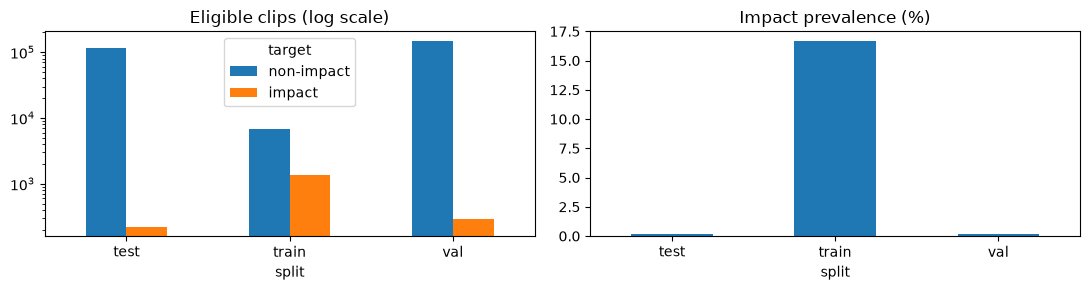

In [2]:
counts = manifest.groupby(['split', 'target']).size().unstack(fill_value=0).rename(columns={0:'non-impact',1:'impact'})
display(counts)
display(manifest.groupby(['split', 'view', 'target']).size().rename('clips').to_frame())
display(manifest.loc[manifest.target.eq(1)].groupby('split').event_id.nunique().rename('heuristic events').to_frame())
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
counts.plot.bar(ax=axes[0], logy=True, rot=0, title='Eligible clips (log scale)')
(100*counts['impact']/counts.sum(axis=1)).plot.bar(ax=axes[1], rot=0, title='Impact prevalence (%)')
plt.tight_layout()
plt.show()

C:\Users\deanr\Computer-Vision-NFL\src\impact\dataset.py:252: UserWarning: Excluding 1 background annotation(s) with frame < 1
  raw = read_labels(labels)


Asterisk: unavailable/ambiguous player position; configured fallback used.


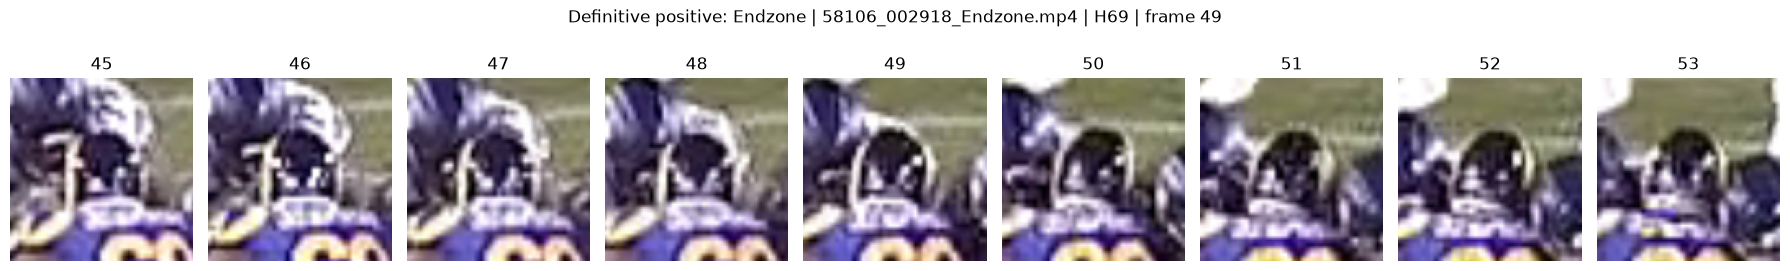

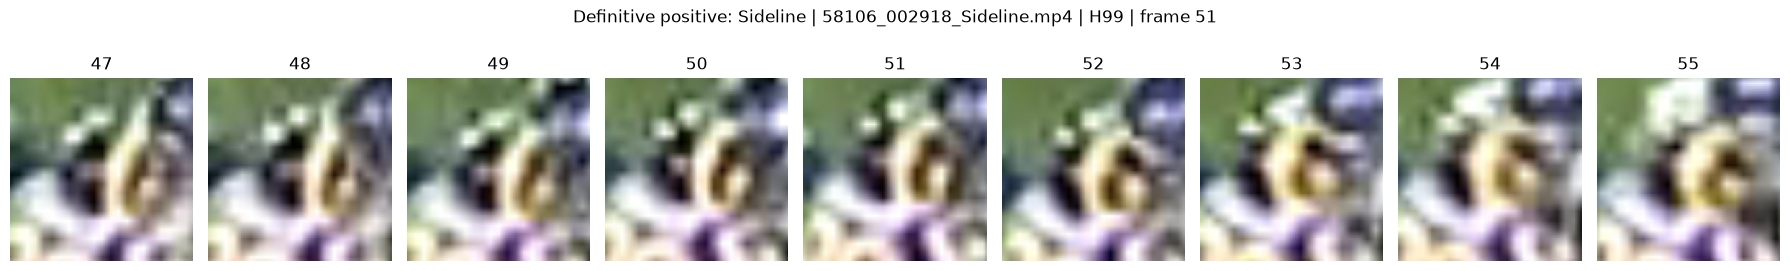

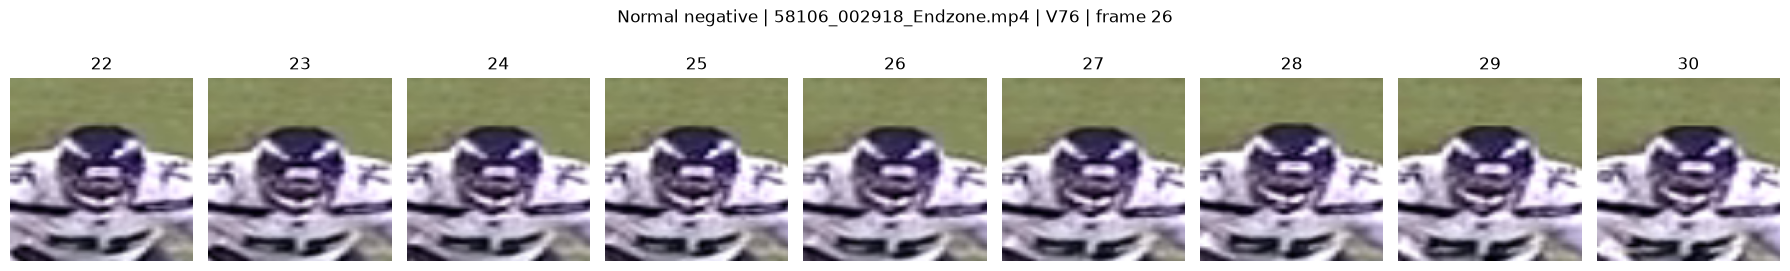

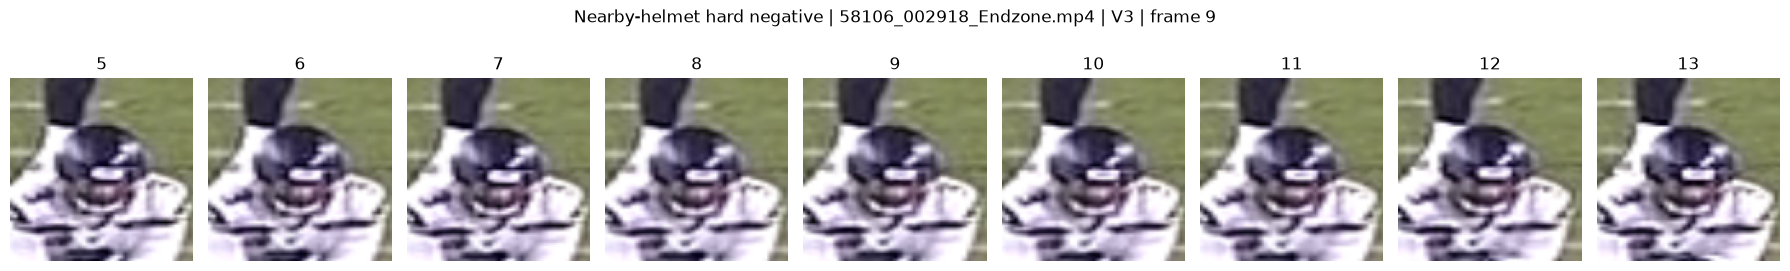

In [3]:
dataset = dataset_for(config, 'train')
def montage(index, title):
    row = dataset.rows.iloc[index]
    frames, boxes, metadata = dataset.raw_clip(index)
    fig, axes = plt.subplots(1, 9, figsize=(18, 3))
    for j, (ax, frame, box) in enumerate(zip(axes, frames, boxes)):
        ax.imshow(crop_rgb(frame, box, config['data']['size'], config['data']['context']))
        suffix = '*' if metadata['missing_positions'][j] else ''
        ax.set_title(f"{metadata['actual_frames'][j]}{suffix}")
        ax.axis('off')
    fig.suptitle(f"{title} | {row.video} | {row.label} | frame {row.frame}")
    plt.tight_layout()
    plt.show()
    return index

positives = dataset.rows.index[dataset.rows.target.eq(1)]
normal = dataset.rows.index[dataset.rows.target.eq(0) & ~dataset.rows.hard_negative]
hard = dataset.rows.index[dataset.rows.target.eq(0) & dataset.rows.hard_negative]
print('Asterisk: unavailable/ambiguous player position; configured fallback used.')
for view in ['Endzone', 'Sideline']:
    indices = dataset.rows.index[dataset.rows.target.eq(1) & dataset.rows.view.eq(view)]
    if len(indices):
        montage(int(indices[0]), f'Definitive positive: {view}')
if len(normal):
    montage(int(normal[0]), 'Normal negative')
if len(hard):
    montage(int(hard[0]), 'Nearby-helmet hard negative')

## Enlarged context and nearby helmets

Red is the original target box; cyan is the enlarged crop. Orange marks other
annotated helmets in the same center frame. Nearby helmets define hard-negative
geometry; they do not by themselves establish an impact.

C:\Users\deanr\AppData\Local\Temp\ipykernel_29320\1988188103.py:2: UserWarning: Excluding 1 background annotation(s) with frame < 1
  source = read_labels(project_path(config['paths']['labels']))


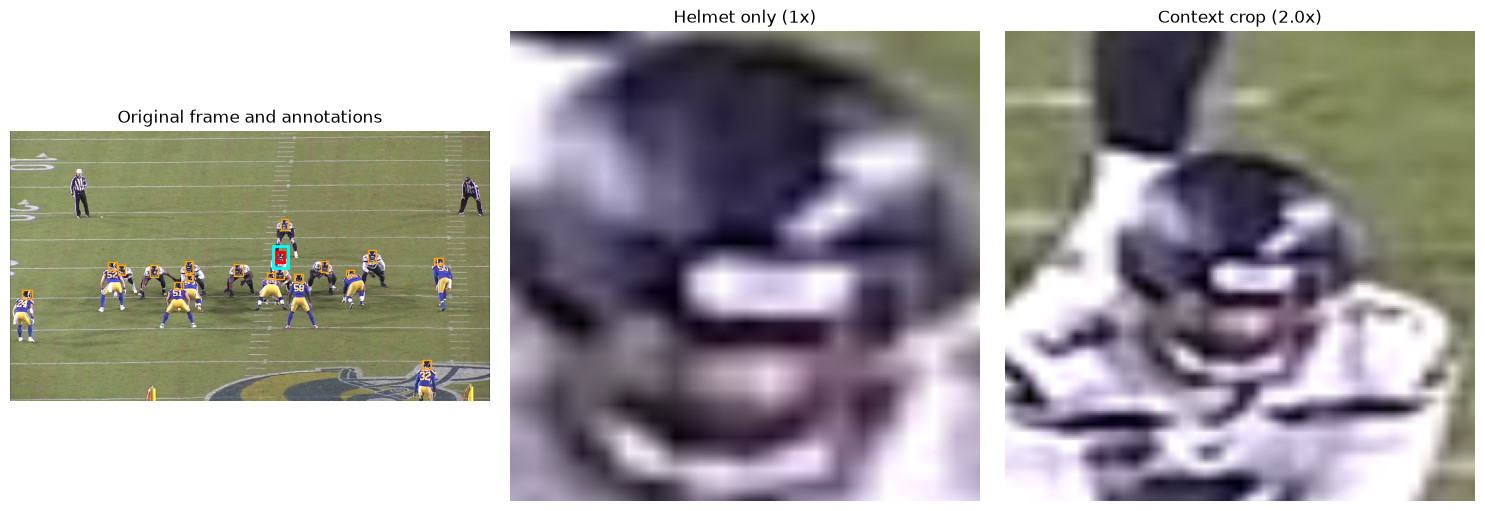

In [4]:
from src.impact.dataset import read_labels
source = read_labels(project_path(config['paths']['labels']))
index = int(hard[0] if len(hard) else positives[0])
row = dataset.rows.iloc[index]
frames, boxes, metadata = dataset.raw_clip(index)
box = row[BOX].to_numpy(float)
x,y,w,h = box
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(frames[4])
neighbors = source.loc[source.video.eq(row.video) & source.frame.eq(row.frame)]
for other in neighbors[BOX].to_numpy():
    axes[0].add_patch(Rectangle(other[:2], *other[2:], fill=False, edgecolor='orange', linewidth=1))
axes[0].add_patch(Rectangle((x,y), w,h,fill=False,edgecolor='red',linewidth=2))
c = config['data']['context']
axes[0].add_patch(Rectangle((x+w/2-w*c/2,y+h/2-h*c/2),w*c,h*c,fill=False,edgecolor='cyan',linewidth=2))
axes[0].set_title('Original frame and annotations')
axes[1].imshow(crop_rgb(frames[4], box, 224, 1))
axes[1].set_title('Helmet only (1x)')
axes[2].imshow(crop_rgb(frames[4], box, 224, c))
axes[2].set_title(f'Context crop ({c}x)')
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

## Batch and synthetic forward-pass check

Input is `[batch, RGB channels, 9, height, width]`. Output is one logit per
clip; sigmoid converts it to probability. Randomly initialized output has no
predictive meaning. No backward pass or optimizer is used.

In [5]:
batch = next(iter(DataLoader(dataset, batch_size=2, num_workers=0)))
print('Real batch:', tuple(batch['clip'].shape), 'labels:', batch['target'].tolist())
assert tuple(batch['clip'].shape[1:]) == (3,9,config['data']['size'],config['data']['size'])
torch.set_num_threads(2)
torch.manual_seed(config['seed'])
model = build_model(pretrained=False).eval()
with torch.inference_mode():
    logits = model(torch.zeros(1,3,9,112,112))
print('Synthetic output:', tuple(logits.shape), 'finite:', bool(torch.isfinite(logits).all()))
assert tuple(logits.shape) == (1,1)
del model

Real batch: (2, 3, 9, 112, 112) labels: [0.0, 0.0]


Synthetic output: (1, 1) finite: True


## Interpretation and next steps

The CSV has no explicit `impact=0` annotations; configuration treats fully blank
impact fields as background. Non-definitive impacts remain excluded. Duplicate
player/frame positions are unavailable for alignment, and the frame-zero background
row is excluded. Black crop borders and repeated boundary frames are deliberate.
These choices and incomplete impact annotation can affect results.

Run `python -m src.impact.train --dry-run` to check the training loader. Begin actual
training later using the explicit command in the Colab guide. Classifier-only metrics
use ground-truth boxes; deployment evaluation must use YOLO candidates on held-out
games. No local trained detector or two-class baseline artifacts were found during setup.